# Parcial 1

Nohelanys Camaño, Kevin Linares, Juan Morales y Ruben Feng

## 1. Carga del dataset

In [ ]:
# Carga del dataset
import pandas as pd

df = pd.read_csv('Balaji Fast Food Sales (1).csv')
df.head()

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening


## 2. Análisis exploratorio inicial (DEA)

In [ ]:
# Análisis exploratorio inicial


print('Filas:', df.shape[0], '| Columnas:', df.shape[1])
df.info()

#Nulos y duplicados
print('\nDuplicados:', df.duplicated().sum())
print('Duplicados sin order_id:', df.drop(columns='order_id').duplicated().sum())
print('\nNulos:\n', df.isnull().sum())

# Valores únicos de las columnas categóricas
for col in ['item_name', 'item_type', 'transaction_type', 'received_by', 'time_of_sale']:
    print('\n', df[col].value_counts(dropna=False))

# Muestra de fechas para revisar formatos
print('\n', df['date'].sample(10, random_state=1))

# Resumen estadístico
df.describe()

Filas: 1000 | Columnas: 10
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            1000 non-null   int64
 1   date                1000 non-null   str  
 2   item_name           1000 non-null   str  
 3   item_type           1000 non-null   str  
 4   item_price          1000 non-null   int64
 5   quantity            1000 non-null   int64
 6   transaction_amount  1000 non-null   int64
 7   transaction_type    893 non-null    str  
 8   received_by         1000 non-null   str  
 9   time_of_sale        1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 78.3 KB

Duplicados: 0
Duplicados sin order_id: 0

Nulos:
 order_id                0
date                    0
item_name               0
item_type               0
item_price              0
quantity                0
transaction_amount      0
transaction_type      107
received

,order_id,item_price,quantity,transaction_amount
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,33.315000,8.162000,275.230000
std,288.819436,14.921744,4.413075,204.402979
min,1.000000,20.000000,1.000000,20.000000
25%,250.750000,20.000000,4.000000,120.000000
50%,500.500000,25.000000,8.000000,240.000000
75%,750.250000,50.000000,12.000000,360.000000
max,1000.000000,60.000000,15.000000,900.000000


### 2.1 Problemas de calidad identificados (antes de modificar)

Nulos en medio de pago: la columna transaction_type tiene 107 nulos (10.7 % de los registros). Solo existen dos medios de pago registrados, efectivo y en línea. Podríamos suponer que esos nulos son de tarjeta, no se puede comprobar.

Corrección de los separadores de las fechas.

No hay duplicados.

Se tradujo el dataset con excepciones.

## 3. Limpieza y traducción de los datos

### 3.1 Diccionarios de traducción (idioma)

In [ ]:
# Diccionarios de traducción al español
columnas = {'order_id': 'id_orden', 'date': 'fecha', 'item_name': 'producto',
            'item_type': 'tipo_producto', 'item_price': 'precio', 'quantity': 'cantidad',
            'transaction_amount': 'monto', 'transaction_type': 'medio_pago',
            'received_by': 'atendido_por', 'time_of_sale': 'turno'}

productos = {'Cold coffee': 'Café frío', 'Sugarcane juice': 'Jugo de caña', 'Sandwich': 'Sándwich',
             'Panipuri': 'Panipuri', 'Aalopuri': 'Aalopuri', 'Vadapav': 'Vadapav', 'Frankie': 'Frankie'}

tipos_producto = {'Fastfood': 'Comida rápida', 'Beverages': 'Bebidas'}
medios_pago = {'Cash': 'Efectivo', 'Online': 'En línea'}
atendido_por = {'Mr.': 'Sr.', 'Mrs.': 'Sra.'}

# Turnos en orden lógico a lo largo del día
turnos = {'Morning': 'Mañana', 'Afternoon': 'Tarde', 'Evening': 'Anochecer',
          'Night': 'Noche', 'Midnight': 'Medianoche'}



Panipuri, Aalopuri, Vadapav y Frankie los dejamos con su nombre original. Son comidas típicas de la India y no tienen una traducción real al español.

### 3.2 Aplicación de la traducción y tratamiento de nulos

In [ ]:
# Tabla completa traducida
df_es = df.copy()
df_es['item_name'] = df_es['item_name'].map(productos)
df_es['item_type'] = df_es['item_type'].map(tipos_producto)
# Primero se traduce y luego se rellenan los nulos: si se rellena antes, .map() vuelve a convertir
# 'Desconocido' en NaN porque no está en el diccionario medios_pago
df_es['transaction_type'] = df_es['transaction_type'].map(medios_pago).fillna('Desconocido')
df_es['received_by'] = df_es['received_by'].map(atendido_por)
df_es['time_of_sale'] = pd.Categorical(df_es['time_of_sale'].map(turnos),
                                       categories=list(turnos.values()), ordered=True)
df_es = df_es.rename(columns=columnas)

# Verificación: ninguna columna debe quedar con nulos después de traducir
print('Nulos después de traducir:\n', df_es.isnull().sum())

# Muestra de la tabla traducida
df_es.head(10)

Nulos después de traducir:
 id_orden         0
fecha            0
producto         0
tipo_producto    0
precio           0
cantidad         0
monto            0
medio_pago       0
atendido_por     0
turno            0
dtype: int64


,id_orden,fecha,producto,tipo_producto,precio,cantidad,monto,medio_pago,atendido_por,turno
0,1,07-03-2022,Aalopuri,Comida rápida,20,13,260,Desconocido,Sr.,Noche
1,2,8/23/2022,Vadapav,Comida rápida,20,15,300,Efectivo,Sr.,Tarde
2,3,11/20/2022,Vadapav,Comida rápida,20,1,20,Efectivo,Sr.,Tarde
3,4,02-03-2023,Jugo de caña,Bebidas,25,6,150,En línea,Sr.,Noche
4,5,10-02-2022,Jugo de caña,Bebidas,25,8,200,En línea,Sr.,Anochecer
5,6,11/14/2022,Vadapav,Comida rápida,20,10,200,Efectivo,Sr.,Anochecer
6,7,05-03-2022,Jugo de caña,Bebidas,25,9,225,Efectivo,Sr.,Anochecer
7,8,12/22/2022,Panipuri,Comida rápida,20,14,280,En línea,Sr.,Noche
8,9,06-10-2022,Panipuri,Comida rápida,20,1,20,Efectivo,Sra.,Mañana
9,10,9/16/2022,Panipuri,Comida rápida,20,5,100,En línea,Sr.,Tarde


### 3.3 Conversión de la fecha a formato de fecha

In [ ]:
# En el DEA se observaron dos formatos: 'MM-DD-YYYY' (con guion) y 'M/D/YYYY' (con barra).
# Se unifica el separador y se convierte con un formato explícito (mes/día/año).
df_es['fecha'] = pd.to_datetime(
    df_es['fecha'].astype(str).str.replace('-', '/', regex=False),
    format='%m/%d/%Y',
    errors='coerce'
)

# Verificación de la conversión
print('Fechas que no se pudieron convertir:', df_es['fecha'].isnull().sum())
print('Rango de fechas:', df_es['fecha'].min().date(), 'a', df_es['fecha'].max().date())
df_es.info()

Fechas que no se pudieron convertir: 0
Rango de fechas: 2022-04-01 a 2023-03-30
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_orden       1000 non-null   int64         
 1   fecha          1000 non-null   datetime64[us]
 2   producto       1000 non-null   str           
 3   tipo_producto  1000 non-null   str           
 4   precio         1000 non-null   int64         
 5   cantidad       1000 non-null   int64         
 6   monto          1000 non-null   int64         
 7   medio_pago     1000 non-null   str           
 8   atendido_por   1000 non-null   str           
 9   turno          1000 non-null   category      
dtypes: category(1), datetime64[us](1), int64(4), str(4)
memory usage: 71.6 KB


### 3.4 Justificación de las decisiones de limpieza

Nulos en medio de pago: Conservamos y etiquetamos los 107 registros nulos como `Desconocido`. Eliminar estas filas implicaría perder el 10.7 % de los datos de ventas y distorsionar los ingresos reales. No se imputaron para no inventar información sin sustento.

Se unificó el formato de las fechas y se convirtieron a tipo fecha. No se encontró ninguna duplicidad.

## 4. Reportes

### 4.1 Reporte por medio de pago
Cantidad de ventas y monto total en efectivo y en línea, con sus porcentajes (cantidad de ventas y montos).

In [ ]:
# Agrupar por medio de pago
reporte_medio_pago = df_es.groupby('medio_pago').agg(
    cantidad_ventas=('id_orden', 'count'),   # cantidad de pedidos por medio de pago
    monto_total=('monto', 'sum')             # monto generado por cada medio de pago
)

# Porcentajes de cantidad de ventas y de monto
reporte_medio_pago['%_cantidad_ventas'] = (
    reporte_medio_pago['cantidad_ventas'] / reporte_medio_pago['cantidad_ventas'].sum() * 100
).round(2)
reporte_medio_pago['%_monto_total'] = (
    reporte_medio_pago['monto_total'] / reporte_medio_pago['monto_total'].sum() * 100
).round(2)

# Orden: efectivo, en línea y al final las ventas sin medio de pago registrado
reporte_medio_pago = reporte_medio_pago.reindex(['Efectivo', 'En línea', 'Desconocido'])

display(reporte_medio_pago)

,cantidad_ventas,monto_total,%_cantidad_ventas,%_monto_total
medio_pago,,,,
Efectivo,476,132840,47.6,48.27
En línea,417,110595,41.7,40.18
Desconocido,107,31795,10.7,11.55


### 4.2 Reporte de productos por turno
Unidades vendidas de Aalopuri, Vadapav y Frankie en cada turno del día.

In [ ]:
producto_busqueda = ["Aalopuri", "Vadapav", "Frankie"]

for producto in producto_busqueda:
    print("Cantidad de ventas de", producto, ":\n", df_es[df_es['producto'] == producto].groupby("turno", observed=False)["cantidad"].sum())
    print("\t\t")

Cantidad de ventas de Aalopuri :
 turno
Mañana        215
Tarde         226
Anochecer     136
Noche         244
Medianoche    223
Name: cantidad, dtype: int64
		
Cantidad de ventas de Vadapav :
 turno
Mañana        195
Tarde         194
Anochecer     199
Noche         183
Medianoche    235
Name: cantidad, dtype: int64
		
Cantidad de ventas de Frankie :
 turno
Mañana        204
Tarde         238
Anochecer     240
Noche         270
Medianoche    198
Name: cantidad, dtype: int64
		


### 4.3 Reporte de tipo de producto por medio de pago

In [ ]:
reporte_tipo_pago = (
  df_es
  .groupby(['tipo_producto', 'medio_pago'])
  .agg(
    unidades=('cantidad', 'sum'),
    ventas=('id_orden', 'count'),
    monto=('monto', 'sum')
  )
  .unstack(fill_value=0)
)

# Agregar el total de cada métrica por tipo de producto
# (se suma por separado para no mezclar unidades, cantidad de ventas y dinero en una sola columna)
for metrica in ['unidades', 'ventas', 'monto']:
  reporte_tipo_pago[(metrica, 'Total')] = reporte_tipo_pago[metrica].sum(axis=1)
reporte_tipo_pago = reporte_tipo_pago[['unidades', 'ventas', 'monto']]

# Agregar total general
reporte_tipo_pago.loc['Total'] = reporte_tipo_pago.sum(axis=0)

reporte_tipo_pago

unidades                              ventas           \
medio_pago    Desconocido Efectivo En línea Total Desconocido Efectivo   
tipo_producto                                                            
Bebidas               376     1255     1008  2639          40      148   
Comida rápida         552     2688     2283  5523          67      328   
Total                 928     3943     3291  8162         107      476   

                                   monto                            
medio_pago    En línea Total Desconocido Efectivo En línea   Total  
tipo_producto                                                       
Bebidas            126   314       12685    41080    32625   86390  
Comida rápida      291   686       19110    91760    77970  188840  
Total              417  1000       31795   132840   110595  275230

### 4.4 Reporte de producto más vendido (por unidades y por ingreso) de cada mes

In [ ]:
# Convertir fechas y crear el mes de cada venta
fechas = pd.to_datetime(df_es['fecha'], errors='coerce', format='mixed')
df_mensual = df_es.assign(
  mes=fechas.dt.to_period('M').astype(str)
)

# Resumen mensual por producto
resumen_mensual = (
  df_mensual
  .groupby(['mes', 'producto'], as_index=False)
  .agg(
    unidades=('cantidad', 'sum'),
    ingreso=('monto', 'sum')
  )
)

# Producto más vendido por unidades e ingreso en cada mes
mas_unidades = (
  resumen_mensual.loc[
    resumen_mensual.groupby('mes')['unidades'].idxmax()
  ]
  .rename(columns={
    'producto': 'producto_mas_unidades',
    'unidades': 'max_unidades'
  })
  [['mes', 'producto_mas_unidades', 'max_unidades']]
)

mas_ingreso = (
  resumen_mensual.loc[
    resumen_mensual.groupby('mes')['ingreso'].idxmax()
  ]
  .rename(columns={
    'producto': 'producto_mas_ingreso',
    'ingreso': 'max_ingreso'
  })
  [['mes', 'producto_mas_ingreso', 'max_ingreso']]
)

reporte_mensual = (
  mas_unidades
  .merge(mas_ingreso, on='mes')
  .sort_values('mes')
)
pd.set_option('display.max_rows', None)
reporte_mensual

,mes,producto_mas_unidades,max_unidades,producto_mas_ingreso,max_ingreso
0,2022-04,Sándwich,125,Sándwich,7500
1,2022-05,Aalopuri,191,Frankie,6850
2,2022-06,Frankie,128,Frankie,6400
3,2022-07,Jugo de caña,122,Sándwich,5400
4,2022-08,Café frío,151,Café frío,6040
5,2022-09,Sándwich,93,Sándwich,5580
6,2022-10,Café frío,156,Café frío,6240
7,2022-11,Panipuri,178,Café frío,6160
8,2022-12,Jugo de caña,152,Café frío,6040
9,2023-01,Frankie,153,Sándwich,8580


## 5. Reportes adicionales

### 5.1 ¿Cuánto efectivo conviene tener en caja en cada turno?

Se toma el efectivo cobrado en cada turno de cada día y se resume por turno. El percentil 75 se usa como monto de referencia: con esa cantidad en caja se cubre el efectivo que se maneja en 3 de cada 4 turnos.

In [ ]:
# Filtrar únicamente las ventas pagadas en efectivo
ventas_efectivo = df_es[
    df_es["medio_pago"] == "Efectivo"
]

# Calcular cuánto efectivo se manejó cada día en cada turno
# observed=True: solo se cuentan los turnos que sí tuvieron ventas en efectivo
# (con observed=False se crean combinaciones fecha-turno vacías con 0 y la mediana queda en 0)
efectivo_diario_turno = (
    ventas_efectivo.groupby(
        ["fecha", "turno"],
        as_index=False,
        observed=True
    )["monto"]
    .sum()
    .rename(columns={
        "monto": "efectivo_diario"
    })
)

# Calcular estadísticas por turno
reporte_efectivo = (
    efectivo_diario_turno.groupby(
        "turno",
        observed=False
    )["efectivo_diario"]
    .agg(
        promedio="mean",
        mediana="median",
        maximo="max"
    )
    .reset_index()
)

# Calcular percentil 75 como monto de referencia
percentil_75 = (
    efectivo_diario_turno.groupby(
        "turno",
        observed=False
    )["efectivo_diario"]
    .quantile(0.75)
    .reset_index(name="efectivo_referencia")
)

# Unir el percentil 75 al reporte
reporte_efectivo = reporte_efectivo.merge(
    percentil_75,
    on="turno"
)

# Redondear los valores
columnas_numericas = [
    "promedio",
    "mediana",
    "maximo",
    "efectivo_referencia"
]

reporte_efectivo[columnas_numericas] = (
    reporte_efectivo[columnas_numericas].round(2)
)

reporte_efectivo

,turno,promedio,mediana,maximo,efectivo_referencia
0,Mañana,289.02,260.0,900,400.0
1,Tarde,320.19,260.0,900,460.0
2,Anochecer,277.93,245.0,965,360.0
3,Noche,362.47,360.0,900,480.0
4,Medianoche,328.58,260.0,1160,480.0


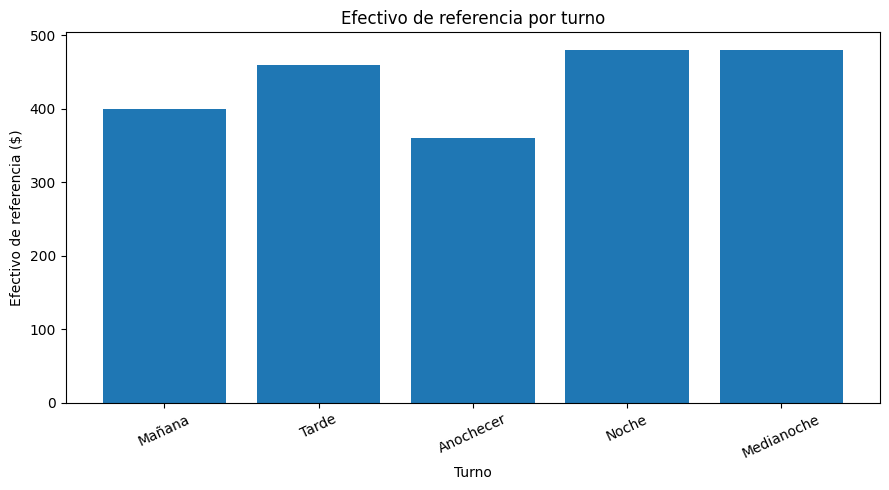

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    reporte_efectivo["turno"].astype(str),
    reporte_efectivo["efectivo_referencia"]
)

plt.title("Efectivo de referencia por turno")
plt.xlabel("Turno")
plt.ylabel("Efectivo de referencia ($)")
plt.xticks(rotation=25)
plt.tight_layout()

plt.show()

### 5.2 ¿Qué productos conviene tener con más inventario en cada quincena?

Se suman las unidades vendidas de cada producto en la primera quincena (días 1 al 15) y en la segunda (días 16 al fin de mes), y se muestran los 3 productos con mayor demanda en cada una.

In [ ]:
import numpy as np

# Crear la columna quincena según el día del mes
df_es["quincena"] = np.where(
    df_es["fecha"].dt.day <= 15,
    "Primera quincena",
    "Segunda quincena"
)

# Sumar las unidades vendidas de cada producto en cada quincena
inventario_quincena = (
    df_es.groupby(
        ["quincena", "producto"],
        as_index=False
    )["cantidad"]
    .sum()
    .rename(columns={
        "cantidad": "unidades_vendidas"
    })
)

# Crear un ranking de productos dentro de cada quincena
inventario_quincena["ranking"] = (
    inventario_quincena
    .groupby("quincena")["unidades_vendidas"]
    .rank(
        method="dense",
        ascending=False
    )
    .astype(int)
)

# Seleccionar los 3 productos con mayor demanda en cada quincena
reporte_inventario = (
    inventario_quincena[
        inventario_quincena["ranking"] <= 3
    ]
    .sort_values(["quincena", "ranking"])
    .reset_index(drop=True)
)

reporte_inventario

,quincena,producto,unidades_vendidas,ranking
0,Primera quincena,Café frío,704,1
1,Primera quincena,Jugo de caña,636,2
2,Primera quincena,Sándwich,612,3
3,Segunda quincena,Panipuri,687,1
4,Segunda quincena,Café frío,657,2
5,Segunda quincena,Jugo de caña,642,3


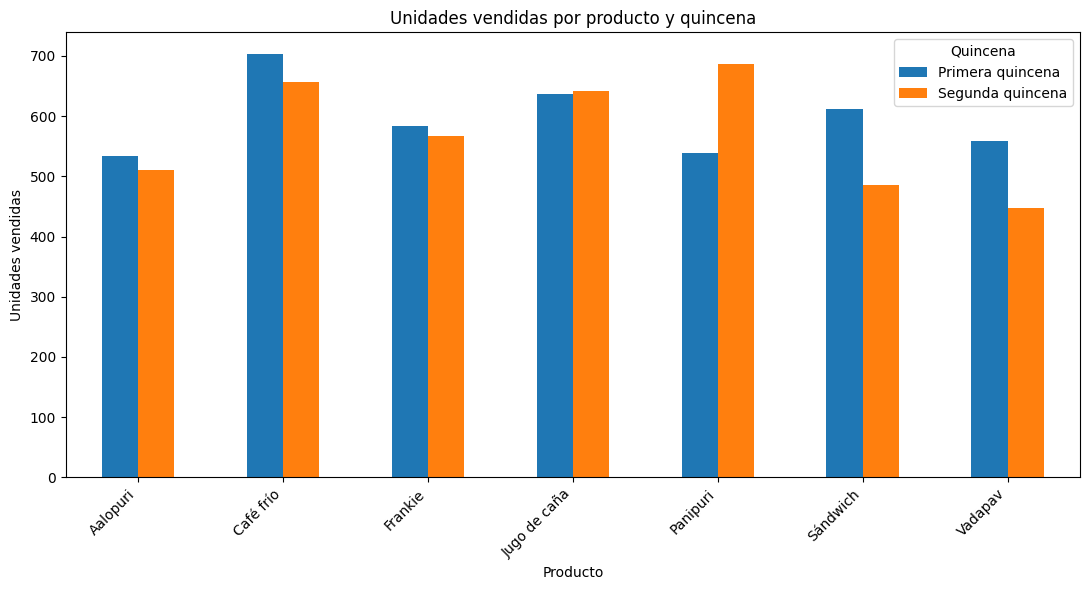

In [ ]:
# Preparar los datos para la gráfica
grafica_inventario = inventario_quincena.pivot(
    index="producto",
    columns="quincena",
    values="unidades_vendidas"
)

# Crear gráfica
grafica_inventario.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Unidades vendidas por producto y quincena")
plt.xlabel("Producto")
plt.ylabel("Unidades vendidas")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Quincena")
plt.tight_layout()

plt.show()

6. Indicadores clave de desempeño (KPI)

KPI 1: Porcentaje del ingreso sin medio de pago registrado

Qué mide: qué parte del dinero vendido no tiene registrado si se cobró en efectivo o en línea, por lo que no se puede cuadrar ni con la caja ni con la cuenta bancaria.

In [ ]:
# Ingreso total del período
ingreso_total = df_es["monto"].sum()

# Ventas que no tienen medio de pago registrado
ventas_sin_registro = df_es[
    df_es["medio_pago"] == "Desconocido"
]

ingreso_sin_registro = ventas_sin_registro["monto"].sum()

# KPI: porcentaje del ingreso sin medio de pago registrado
kpi_sin_registro = round(
    ingreso_sin_registro / ingreso_total * 100,
    2
)

# Ticket promedio por medio de pago (para dar contexto al KPI)
ticket_por_medio = (
    df_es.groupby("medio_pago")["monto"]
    .mean()
    .round(2)
    .reindex(["Efectivo", "En línea", "Desconocido"])
)

print("Ingreso total:", ingreso_total)
print("Ingreso sin medio de pago registrado:", ingreso_sin_registro)
print("Pedidos sin medio de pago registrado:", len(ventas_sin_registro), "de", len(df_es))
print("KPI - % del ingreso sin medio de pago registrado:", kpi_sin_registro, "%")
print("\\nTicket promedio por medio de pago:\\n", ticket_por_medio)

Ingreso total: 275230
Ingreso sin medio de pago registrado: 31795
Pedidos sin medio de pago registrado: 107 de 1000
KPI - % del ingreso sin medio de pago registrado: 11.55 %
\nTicket promedio por medio de pago:\n medio_pago
Efectivo       279.08
En línea       265.22
Desconocido    297.15
Name: monto, dtype: float64


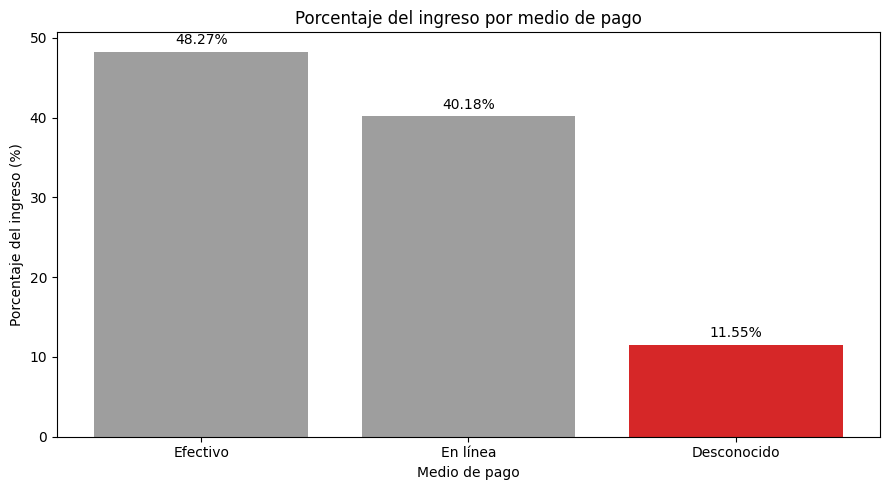

In [ ]:
import matplotlib.pyplot as plt

# Porcentaje del ingreso por medio de pago
porcentaje_ingreso_medio = (
    df_es.groupby("medio_pago")["monto"]
    .sum()
    .div(ingreso_total)
    .mul(100)
    .round(2)
    .reindex(["Efectivo", "En línea", "Desconocido"])
)

# Resaltar en otro color la parte sin registro
colores = ["#9e9e9e", "#9e9e9e", "#d62728"]

plt.figure(figsize=(9, 5))

barras = plt.bar(
    porcentaje_ingreso_medio.index,
    porcentaje_ingreso_medio.values,
    color=colores
)

# Etiquetas con el porcentaje sobre cada barra
plt.bar_label(
    barras,
    labels=[f"{valor}%" for valor in porcentaje_ingreso_medio.values],
    padding=3
)

plt.title("Porcentaje del ingreso por medio de pago")
plt.xlabel("Medio de pago")
plt.ylabel("Porcentaje del ingreso (%)")
plt.tight_layout()

plt.show()

Resultado: el 11.55 % del ingreso (31,795 de 275,230) viene de 107 pedidos sin medio de pago registrado. Además, esos pedidos tienen el ticket promedio más alto (297, contra 279 en efectivo y 265 en línea).

Decisión: el dueño puede hacer obligatorio registrar el medio de pago en cada venta y revisar en qué turnos o con qué empleado se quedan más ventas sin registrar. La meta sería llevar este indicador a 0 %.

KPI 2: Dependencia de pedidos grandes

Qué mide: qué porcentaje del ingreso sale de los pedidos grandes (10 unidades o más), comparado con qué porcentaje de los pedidos representan.

In [ ]:
# Clasificar cada pedido según la cantidad de unidades
df_es["tamano_pedido"] = np.where(
    df_es["cantidad"] >= 10,
    "Grande (10 o más)",
    "Pequeño (menos de 10)"
)

# Porcentaje de pedidos y de ingreso por tamaño de pedido
reporte_tamano = (
    df_es.groupby("tamano_pedido")
    .agg(
        pedidos=("id_orden", "count"),
        ingreso=("monto", "sum")
    )
)

reporte_tamano["%_pedidos"] = (
    reporte_tamano["pedidos"] / reporte_tamano["pedidos"].sum() * 100
).round(2)

reporte_tamano["%_ingreso"] = (
    reporte_tamano["ingreso"] / reporte_tamano["ingreso"].sum() * 100
).round(2)

# KPI: porcentaje del ingreso que viene de pedidos grandes
kpi_pedidos_grandes = reporte_tamano.loc["Grande (10 o más)", "%_ingreso"]

print("KPI - % del ingreso que viene de pedidos grandes:", kpi_pedidos_grandes, "%")
print(
    "Esos pedidos son el",
    reporte_tamano.loc["Grande (10 o más)", "%_pedidos"],
    "% del total de pedidos"
)

reporte_tamano

KPI - % del ingreso que viene de pedidos grandes: 65.14 %
Esos pedidos son el 42.4 % del total de pedidos


,pedidos,ingreso,%_pedidos,%_ingreso
tamano_pedido,,,,
Grande (10 o más),424,179280,42.4,65.14
Pequeño (menos de 10),576,95950,57.6,34.86


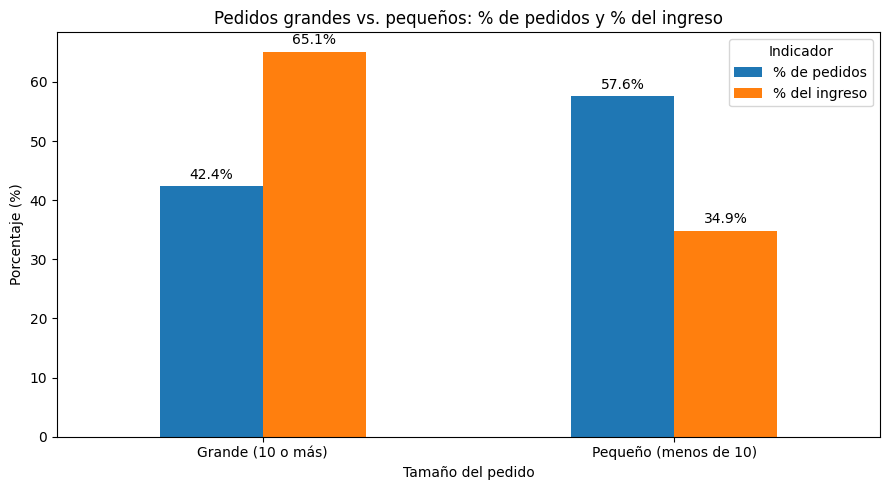

In [ ]:
# Preparar los datos para la gráfica
grafica_tamano = reporte_tamano[["%_pedidos", "%_ingreso"]].rename(columns={
    "%_pedidos": "% de pedidos",
    "%_ingreso": "% del ingreso"
})

# Crear gráfica
ax = grafica_tamano.plot(
    kind="bar",
    figsize=(9, 5)
)

# Etiquetas con el porcentaje sobre cada barra
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f%%",
        padding=3
    )

plt.title("Pedidos grandes vs. pequeños: % de pedidos y % del ingreso")
plt.xlabel("Tamaño del pedido")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.legend(title="Indicador")
plt.tight_layout()

plt.show()

Resultado: los pedidos de 10 unidades o más son el 42.4 % de los pedidos, pero generan el 65.14 % del ingreso. Menos de la mitad de los pedidos trae casi dos tercios del dinero.

Decisión: el negocio depende bastante de los clientes que compran en cantidad (grupos, oficinas, pedidos para llevar). El dueño puede cuidarlos con combos o descuentos por volumen y pedidos por encargo, y al mismo tiempo buscar subir lo que gastan los pedidos pequeños, por ejemplo ofreciendo una bebida junto con la comida.

# 7. Hallazgos

1 El sándwich, el Frankie y el café frío dejan casi dos terceras partes del dinero.

2 La noche es el turno que más vende y, junto con la medianoche, el que más efectivo maneja: conviene tener más cambio en caja y más personal.

3 Las ventas van creciendo: de enero a marzo de 2023 se vendió cerca de un 29 % más que de abril a junio de 2022.